# Expanded heat EEG pilot

How much do reported ratings differ when the same person receives similar heat, after screening the corresponding EEG? This is a descriptive check to guide the choice of hypothesis.

We kept the original three participants and drew 12 more from the same EEG system and thermode group using a fixed seed, before reading their EEG or ratings. Expansion covers the rated heat task. The source is [OpenNeuro ds008349 v2.0.1](https://openneuro.org/datasets/ds008349/versions/2.0.1).

In [1]:
from itertools import combinations
import json
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

root = Path("data/raw/ds008349-2.0.1")
original = ["sub-086", "sub-089", "sub-092"]
metadata = pd.read_csv(root / "participants.tsv", sep="\t")
issues = metadata["thermalactive_import_issues"].fillna("")
eligible = (
    metadata["eeg_system"].eq("BrainProducts - Actichamp Plus")
    & metadata["thermode"].eq("TCS")
    & metadata["thermalactive_dur"].ge(490)
    & metadata["thermalactive_nchans_eeg"].eq(63)
    & metadata["thermalactive_sfreq"].eq(1000)
    & ~issues.str.contains("no rating|999|temperature.+(?:inferred|not recorded)", case=False)
    & ~metadata["participant_id"].isin(original)
)
new = sorted(metadata.loc[eligible, "participant_id"].sort_values().sample(12, random_state=8349))
participants = sorted(original + new)

# Verify that the downloaded subset is the subset chosen from metadata.
manifest = json.loads((root / "expanded-heat-download-manifest.json").read_text())
assert manifest["version"] == "2.0.1"
assert sorted(f"sub-{subject}" for subject in manifest["subjects"]) == new
print(f"{len(new)} of {eligible.sum()} eligible new participants sampled. Total: {len(participants)}.")
print(", ".join(participants))

12 of 71 eligible new participants sampled. Total: 15.
sub-055, sub-058, sub-061, sub-062, sub-065, sub-083, sub-086, sub-089, sub-092, sub-109, sub-111, sub-113, sub-121, sub-127, sub-131


## Make one-second EEG checks inside each heat plateau

Start 25 seconds after the block marker and inspect the next 10 seconds, as in the first pilot. Read the delivered temperature and the rating along with the EEG. Check the recording has nine labeled blocks and an end marker, that the inspection windows fit inside each block, and that the stimulus channel agrees with the programmed level across the window.

For each one-second interval, find the peak-to-peak voltage for each scalp channel. The primary screen keeps a second if all 63 EEG channels have finite values, with peak-to-peak voltages from **0.5 to 150 µV**. The lower limit flags nearly flat channels. The upper limit carries forward the earlier pilot's visual inspection threshold. Neither threshold identifies the source of an artifact. A noisy channel can cause an entire second to fail.

The temperature and rating are summarized by their median within each second. Keep the rating units defined by the release, and treat negative values and 999 as missing. If EEG quality fails, the ratings may still be valid for the before-screen comparison.

In [2]:
def open_heat_run(subject):
    prefix = root / subject / "eeg" / f"{subject}_task-thermalactive"
    channels = pd.read_csv(f"{prefix}_channels.tsv", sep="\t")
    eeg = channels.loc[channels["type"] == "EEG", "name"].tolist()
    eog = channels.loc[channels["type"] == "EOG", "name"].tolist()
    misc = channels.loc[~channels["type"].isin(["EEG", "EOG"]), "name"].tolist()
    raw = mne.io.read_raw_brainvision(f"{prefix}_eeg.vhdr", eog=eog, misc=misc,
                                     preload=False, ignore_marker_types=True, verbose="ERROR")
    fs = int(raw.info["sfreq"])
    events = pd.read_csv(f"{prefix}_events.tsv", sep="\t")
    assert fs == 1000 and len(eeg) == 63, subject
    assert len(events) == 10 and events.iloc[-1]["trial_type"].endswith("/end"), subject
    assert (np.abs(np.rint(events["onset"] * fs) - events["sample"]) <= 1).all(), subject
    assert events["trial_type"].tolist() == raw.annotations.description.tolist(), subject


    return raw, eeg, events, prefix, fs

window_rows = []
log_rows = 0
max_marker_ms = 0
for subject in participants:
    raw, eeg, events, prefix, fs = open_heat_run(subject)
    marker_ms = 1000 * np.abs(events['onset'].to_numpy() - raw.annotations.onset).max()
    max_marker_ms = max(max_marker_ms, marker_ms)
    # Check the separate rating log against the rating on the EEG clock.
    log = pd.read_csv(f"{prefix}_stim.tsv.gz", sep="\t")
    log_samples = np.rint(log["times (s)"] * fs).to_numpy(dtype=int)
    assert ((log_samples >= 0) & (log_samples < raw.n_times)).all(), subject
    embedded = raw.get_data(picks=["rating"])[0][log_samples]
    assert np.allclose(embedded, log["rating"], rtol=0, atol=1e-6), subject
    log_rows += len(log)


    for index, event in events.iloc[:-1].iterrows():
        block, level_text = event["trial_type"].split("/p")
        level = int(level_text)
        start = int(event["sample"]) + 25 * fs
        stop = start + 10 * fs
        assert start >= 0 and stop <= min(events.iloc[index + 1]["sample"], raw.n_times), (subject, block)

        eeg_data = raw.get_data(picks=eeg, start=start, stop=stop).reshape(len(eeg), 10, fs)
        ptp = np.ptp(eeg_data, axis=2) * 1e6
        stimulus, temperature, ratings = raw.get_data(
            picks=["stim", "thermode", "rating"], start=start, stop=stop,
        ).reshape(3, 10, fs)
        assert np.allclose(stimulus, level), (subject, block)
        valid_rating = np.isfinite(ratings) & (ratings >= 0) & (ratings != 999)
        valid_temperature = np.isfinite(temperature) & (temperature > 0)
        for second in range(10):
            # Require valid temperature and ratings throughout the second.
            labels_valid = bool(valid_rating[second].all() and valid_temperature[second].all())
            amplitudes = ptp[:, second]
            window_rows.append({
                "Participant": subject, "Block": block, "Level": level, "Second": 25 + second,
                "Temperature °C": float(np.median(temperature[second])),
                "Rating": float(np.median(ratings[second])),
                "Labels valid": labels_valid,
                "All channels finite and above floor": bool((np.isfinite(amplitudes) & (amplitudes >= 0.5)).all()),
                "Maximum channel µV": float(amplitudes.max()),
            })

windows = pd.DataFrame(window_rows)
assert len(windows) == 15 * 9 * 10
eeg_pass = windows["All channels finite and above floor"] & windows["Maximum channel µV"].le(150)
print(f"Evaluated {len(windows):,} one-second intervals across {windows.groupby(['Participant', 'Block']).ngroups} heat blocks.")
print(f"All {log_rows:,} rating log values matched. Largest marker timing difference: {max_marker_ms:.1f} ms.")
print(f"Valid temperature and rating throughout: {windows['Labels valid'].sum():,}/{len(windows):,} seconds.")
print(f"Passed primary EEG amplitude screen: {eeg_pass.sum():,}/{len(windows):,} seconds.")

Evaluated 1,350 one-second intervals across 135 heat blocks.
All 375,000 rating log values matched. Largest marker timing difference: 1.0 ms.
Valid temperature and rating throughout: 1,350/1,350 seconds.
Passed primary EEG amplitude screen: 719/1,350 seconds.


## Compare repeats at matched temperature and time within the block

Compare each pair of repeats at the same programmed level within a person. Match seconds by time since the block marker, so 25–26 seconds in one block is compared with 25–26 seconds in the other. A pair starts with at least five corresponding seconds with valid labels and measured temperatures within **0.10°C**. After EEG screening, at least five of those corresponding seconds must pass in both blocks.

For a retained pair, take the median rating across the retained seconds in each block and report the absolute difference. Also calculate the difference on the temperature-matched seconds before screening, using the **same retained pairs**. This helps separate a change within retained pairs from the loss of pairs altogether. Pairs can share blocks. Report participant counts and participant-level medians alongside pair counts, and avoid treating the pair count as an independent sample size.

In [3]:
# Group once. Every block's rows are in the same relative-second order.
potential_pairs = []
for (subject, level), at_level in windows.groupby(["Participant", "Level"]):
    block_rows = list(at_level.groupby("Block"))
    assert len(block_rows) == 3, (subject, level)
    for (block_a, a), (block_b, b) in combinations(block_rows, 2):
        assert np.array_equal(a["Second"], b["Second"])
        potential_pairs.append((subject, int(level), block_a, block_b, a, b))

def compare_pairs(max_uv=150, temperature_tolerance=0.10, minimum_seconds=5, block_pairs=None):
    rows = []
    if block_pairs is None:
        block_pairs = potential_pairs
    for subject, level, block_a, block_b, a, b in block_pairs:
        delta_t = np.abs(a["Temperature °C"].to_numpy() - b["Temperature °C"].to_numpy())
        matched = a["Labels valid"].to_numpy() & b["Labels valid"].to_numpy() & (delta_t <= temperature_tolerance + 1e-9)
        if matched.sum() < minimum_seconds:
            continue

        passed_a = a["All channels finite and above floor"].to_numpy() & (a["Maximum channel µV"].to_numpy() <= max_uv)
        passed_b = b["All channels finite and above floor"].to_numpy() & (b["Maximum channel µV"].to_numpy() <= max_uv)
        retained = matched & passed_a & passed_b
        kept = retained.sum() >= minimum_seconds
        rating_a, rating_b = a["Rating"].to_numpy(), b["Rating"].to_numpy()

        change_before = np.median(rating_b[matched]) - np.median(rating_a[matched])
        change_after = np.median(rating_b[retained]) - np.median(rating_a[retained]) if kept else np.nan
        rows.append({
            "Participant": subject, "Level": level, "First block": block_a, "Second block": block_b,
            "Temperature-matched seconds": int(matched.sum()), "Retained seconds": int(retained.sum()),
            "Rating gap before": abs(change_before), "Signed change before": change_before,
            "Rating gap after": abs(change_after), "Signed change after": change_after,
            "First rating after": np.median(rating_a[retained]) if kept else np.nan,
            "Second rating after": np.median(rating_b[retained]) if kept else np.nan,
            "First temperature after (°C)": np.median(a["Temperature °C"].to_numpy()[retained]) if kept else np.nan,
            "Second temperature after (°C)": np.median(b["Temperature °C"].to_numpy()[retained]) if kept else np.nan,
        })
    return pd.DataFrame(rows)

def participant_summary(pairs):
    kept = pairs.dropna(subset=["Rating gap after"])
    people = kept.groupby("Participant")["Rating gap after"].agg(
        pairs="size", median_gap="median", max_gap="max"
    ).reindex(participants)
    people["pairs"] = people["pairs"].fillna(0).astype(int)
    return people

primary = compare_pairs()
retained = primary.dropna(subset=["Rating gap after"])
people = participant_summary(primary)

print(f"Temperature-matched pairs before EEG screen: {len(primary)}/{len(potential_pairs)}.")
print(f"Retained EEG pairs: {len(retained)}/{len(primary)}, from {len(retained['Participant'].unique())}/{len(participants)} participants.")
print(f"Median gap before screening across all temperature-matched pairs: {primary['Rating gap before'].median():.1f} rating units.")
print(f"Median gap before and after on the same retained pairs: {retained['Rating gap before'].median():.1f} → {retained['Rating gap after'].median():.1f} rating units.")
display(people.round(1))
display(retained.nlargest(5, "Rating gap after")[[
    "Participant", "Level", "First block", "Second block", "Retained seconds",
    "First temperature after (°C)", "Second temperature after (°C)",
    "First rating after", "Second rating after", "Rating gap after",
]].round(2))

Temperature-matched pairs before EEG screen: 135/135.
Retained EEG pairs: 41/135, from 8/15 participants.
Median gap before screening across all temperature-matched pairs: 20.0 rating units.
Median gap before and after on the same retained pairs: 16.0 → 16.0 rating units.


,pairs,median_gap,max_gap
Participant,,,
sub-055,0,NaN,NaN
sub-058,0,NaN,NaN
sub-061,1,0.0,0.0
sub-062,0,NaN,NaN
sub-065,7,20.0,38.0
sub-083,3,64.0,70.0
sub-086,6,21.0,52.0
sub-089,4,4.5,6.0
sub-092,0,NaN,NaN


,Participant,Level,First block,Second block,Retained seconds,First temperature after (°C),Second temperature after (°C),First rating after,Second rating after,Rating gap after
93,sub-111,100,t03,t06,5,45.22,45.22,148.0,0.0,148.0
117,sub-127,50,t01,t04,10,40.97,41.00,14.0,102.0,88.0
97,sub-111,150,t02,t07,6,46.56,46.52,66.0,140.0,74.0
45,sub-083,50,t01,t04,9,44.68,44.68,16.0,86.0,70.0
119,sub-127,50,t04,t08,10,41.00,41.00,102.0,34.0,68.0


## Vary the screening rules

Check how the answer changes when the EEG limit or temperature tolerance changes, one at a time. Also ask what happens if seven seconds must survive. All rows use the same participants and blocks. The “at least 20” count is an illustrative gap in released rating units, with no clinical cutoff implied.

Pay attention to how many participants still contribute. A stable median among retained pairs can coexist with a large change in who remains.

In [4]:
settings = [
    ("Stricter EEG limit", 100, 0.10, 5),
    ("Primary", 150, 0.10, 5),
    ("Looser EEG limit", 200, 0.10, 5),
    ("Closer temperature match", 150, 0.05, 5),
    ("Wider temperature match", 150, 0.20, 5),
    ("More shared seconds", 150, 0.10, 7),
]
sensitivity_rows = []
for name, limit, tolerance, minimum in settings:
    candidates = compare_pairs(limit, tolerance, minimum)
    kept = candidates.dropna(subset=["Rating gap after"])
    by_participant = participant_summary(candidates)
    gaps = kept["Rating gap after"]
    sensitivity_rows.append({
        "Rule": name, "EEG limit (µV)": limit, "Tolerance (°C)": tolerance,
        "Minimum seconds": minimum, "Temperature-matched pairs": len(candidates),
        "Retained pairs": len(kept), "Participants": int((by_participant["pairs"] > 0).sum()),
        "Median pair gap": gaps.median(),
        "Median of participant medians": by_participant["median_gap"].median(),
        "Participants with any gap ≥20": int(by_participant["max_gap"].ge(20).sum()),
    })
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(1))

,Rule,EEG limit (µV),Tolerance (°C),Minimum seconds,Temperature-matched pairs,Retained pairs,Participants,Median pair gap,Median of participant medians,Participants with any gap ≥20
0,Stricter EEG limit,100,0.1,5,135,4,2,21.0,28.0,2
1,Primary,150,0.1,5,135,41,8,16.0,20.0,6
2,Looser EEG limit,200,0.1,5,135,89,12,16.0,19.0,11
3,Closer temperature match,150,0.0,5,124,37,8,16.0,11.8,6
4,Wider temperature match,150,0.2,5,135,42,8,17.0,20.0,6
5,More shared seconds,150,0.1,7,135,27,8,16.0,14.5,5


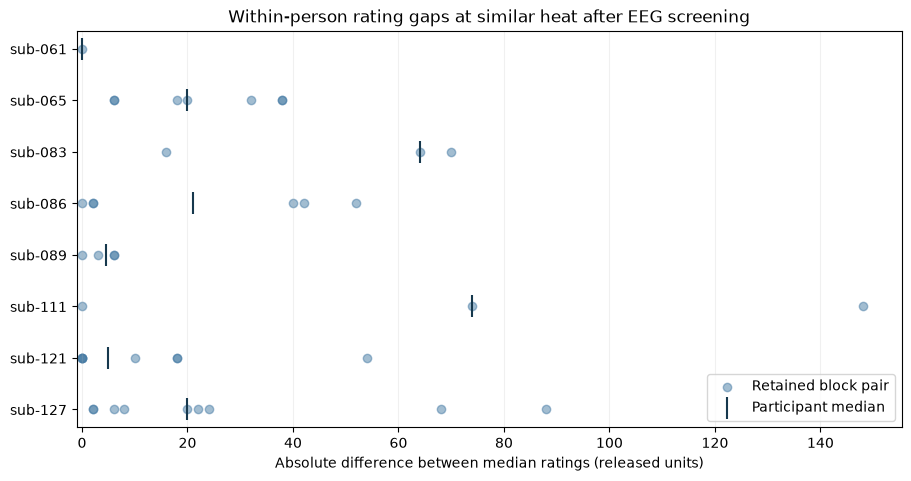

In [5]:
with_data = people.dropna(subset=["median_gap"])
fig, ax = plt.subplots(figsize=(9, 4.7), layout="constrained")
for position, (subject, person) in enumerate(with_data.iterrows()):
    gaps = retained.loc[retained["Participant"].eq(subject), "Rating gap after"]
    ax.scatter(gaps, np.full(len(gaps), position), color="#477ca5", alpha=0.5)
    ax.scatter(person["median_gap"], position, color="#16384d", marker="|", s=250, zorder=3)
ax.set(
    yticks=range(len(with_data)), yticklabels=with_data.index,
    xlabel="Absolute difference between median ratings (released units)",
    title="Within-person rating gaps at similar heat after EEG screening",
)
ax.invert_yaxis()
ax.set_xlim(left=-1)
ax.grid(axis="x", alpha=0.18)
ax.scatter([], [], color="#477ca5", alpha=0.5, label="Retained block pair")
ax.scatter([], [], color="#16384d", marker="|", s=250, label="Participant median")
ax.legend(loc="lower right")
plt.show()

**Try it yourself.** Open the table of retained pairs and trace one row back to the two block markers in the source file. Count how many seconds were available in both blocks. In the sensitivity table, compare what changes when the amplitude limit is stricter. Explain why fewer retained EEG seconds could affect who appears in the result.

The comparisons establish how much rating variation remains under the pilot's screening rules. Block order, adaptation, and rating behavior may still affect those differences. This pilot leaves the hypothesis open and does not estimate a relationship between EEG features and pain ratings.

## Follow-up · Does a shared block-order pattern explain the rating gaps?

Keep the sign of each contrast. A negative number means the later block was rated lower. A positive number means it was rated higher. Compare the first and third repeats of each programmed level, then check the schedule against the event files. Repetition, time in the session, and the history of preceding stimuli may travel together.

As a check on how much a *shared* order pattern explains, take the median signed change for the same block contrast among all other participants. Use that median to predict the held-out participant's signed change. Compare the typical absolute error against a simple prediction of no change. This is a descriptive out-of-person check across the 15 runs. Participants contribute multiple contrasts, and the pair count is not an independent sample size.

In [6]:
design = windows[["Participant", "Block", "Level"]].drop_duplicates().sort_values(
    ["Participant", "Block"]
)
sequences = design.groupby("Participant")["Level"].agg(tuple)
print("Distinct heat schedules:", sequences.nunique())
print("Sequence:", " → ".join(str(level) for level in sequences.iloc[0]))

design["Repeat"] = design.groupby(["Participant", "Level"]).cumcount() + 1
repeat_lookup = design.set_index(["Participant", "Block"])["Repeat"]
def number_repeats(pairs):
    order = pairs.copy()
    for position in ("First", "Second"):
        order[f"{position} repeat"] = [
            repeat_lookup.loc[subject, block]
            for subject, block in zip(order["Participant"], order[f"{position} block"])
        ]
    return order

order = number_repeats(primary)

order_rows = []
for label, signed in [("Before EEG screen", "Signed change before"),
                      ("After primary EEG screen", "Signed change after")]:
    for start, end in [(1, 2), (2, 3), (1, 3)]:
        contrast = order.loc[order["First repeat"].eq(start) & order["Second repeat"].eq(end)]
        available = contrast.dropna(subset=[signed])
        values = available[signed]
        order_rows.append({
            "Screen": label, "Repeats": f"{start} → {end}",
            "Participants": available["Participant"].nunique(), "Pairs": len(available),
            "Median signed change": values.median(),
            "Later lower": int((values < 0).sum()), "Unchanged": int((values == 0).sum()),
            "Later higher": int((values > 0).sum()),
            "Median of participant medians": available.groupby("Participant")[signed].median().median(),
        })

order_summary = pd.DataFrame(order_rows)
display(order_summary.round(2))

def shared_order_errors(pairs, signed):
    current = pairs.dropna(subset=[signed])
    adjusted_rows = []
    for subject, test_rows in current.groupby("Participant"):
        # Predict the signed gap from other participants with the same level and repeat contrast.
        others = current.loc[current["Participant"].ne(subject)]
        reference = others.groupby(["Level", "First repeat", "Second repeat"])[signed].median()
        for _, test in test_rows.iterrows():
            key = (test["Level"], test["First repeat"], test["Second repeat"])
            if key not in reference.index:
                continue
            gap = test[signed]
            adjusted_rows.append({
                "Participant": subject, "No-change error": abs(gap),
                "Shared-order error": abs(gap - reference.loc[key]),
            })

    return pd.DataFrame(adjusted_rows)

adjusted = pd.concat([
    shared_order_errors(order, "Signed change before").assign(Screen="Before EEG screen"),
    shared_order_errors(order, "Signed change after").assign(Screen="After primary EEG screen"),
], ignore_index=True)

display(adjusted.groupby("Screen").agg(
    comparable_pairs=("Participant", "size"), participants=("Participant", "nunique"),
    median_no_change_error=("No-change error", "median"), median_shared_order_error=("Shared-order error", "median"),
).round(2))
person_errors = adjusted.groupby(["Screen", "Participant"])[["No-change error", "Shared-order error"]].median()
display(person_errors.groupby("Screen").median().round(2))

Distinct heat schedules: 1
Sequence: 50 → 150 → 100 → 50 → 150 → 100 → 150 → 50 → 100


,Screen,Repeats,Participants,Pairs,Median signed change,Later lower,Unchanged,Later higher,Median of participant medians
0,Before EEG screen,1 → 2,15,45,0.0,16,7,22,0.0
1,Before EEG screen,2 → 3,15,45,2.0,15,7,23,0.0
2,Before EEG screen,1 → 3,15,45,2.0,14,8,23,0.0
3,After primary EEG screen,1 → 2,8,17,0.0,7,4,6,-4.5
4,After primary EEG screen,2 → 3,5,11,0.0,5,2,4,0.0
5,After primary EEG screen,1 → 3,6,13,2.0,4,2,7,3.0


,comparable_pairs,participants,median_no_change_error,median_shared_order_error
Screen,,,,
After primary EEG screen,41,8,16.0,24.0
Before EEG screen,135,15,20.0,21.0


,No-change error,Shared-order error
Screen,,
After primary EEG screen,20.0,28.0
Before EEG screen,20.0,20.0


## Follow-up · Do ratings drift within a plateau, and which channels fail?

Compare **15–20 seconds** with **30–35 seconds** within each block. Match the first early second with the first late second, and so on. Use the 0.10°C tolerance and require at least three corresponding seconds. Positive values mean ratings rose during the plateau. Rating adjustment and reporting lag can also contribute, so this is a check for drift compatible with adaptation.

For EEG exclusions, record which scalp channels fail each one-second check. Use **15–25 seconds** of every block to rank the channels for each person. Test the effect of omitting up to two that fail most often on the separate original **25–35-second** intervals. The ranking uses EEG voltages and no ratings. It is a within-run sensitivity check, so an electrode that frequently picks up blinks could rank highly without being faulty.

In [7]:
def samples_by_second(raw, channels, start, stop, fs):
    data = raw.get_data(picks=channels, start=start, stop=stop)
    return data.reshape(len(channels), -1, fs)

def peak_to_peak_failures(data, upper=150):
    amplitude = np.ptp(data, axis=2) * 1e6
    fails = ~np.isfinite(amplitude) | (amplitude < 0.5) | (amplitude > upper)
    return amplitude, fails

channel_rows, screen_rows, drift_rows = [], [], []
for subject in participants:
    raw, eeg, events, _, fs = open_heat_run(subject)
    channel_counts = np.zeros(len(eeg), dtype=int)
    block_metrics = []

    for _, event in events.iloc[:-1].iterrows():
        block, level_text = event["trial_type"].split("/p")
        level = int(level_text)
        start = int(event["sample"]) + 15 * fs
        stop = start + 20 * fs
        eeg_seconds = samples_by_second(raw, eeg, start, stop, fs)
        amplitude, fails = peak_to_peak_failures(eeg_seconds)
        stimulus, temperature, ratings = samples_by_second(
            raw, ["stim", "thermode", "rating"], start, stop, fs,
        )
        channel_counts += fails[:, :10].sum(axis=1)
        block_metrics.append((block, amplitude[:, 10:], fails[:, 10:]))

        early, late = slice(0, 5), slice(15, 20)
        assert np.allclose(stimulus[early], level) and np.allclose(stimulus[late], level)
        temp = np.median(temperature, axis=1)
        rating = np.median(ratings, axis=1)
        valid = (
            np.all(np.isfinite(temperature) & (temperature > 0), axis=1)
            & np.all(np.isfinite(ratings) & (ratings >= 0) & (ratings != 999), axis=1)
        )
        matched = valid[early] & valid[late] & (np.abs(temp[early] - temp[late]) <= 0.10 + 1e-9)
        passes = ~fails.any(axis=0)
        clean = matched & passes[early] & passes[late]
        drift_rows.append({
            "Participant": subject, "Block": block, "Level": level,
            "Matched seconds": int(matched.sum()), "Retained seconds": int(clean.sum()),
            "Signed drift before": np.median(rating[late][matched] - rating[early][matched]) if matched.sum() >= 3 else np.nan,
            "Signed drift after": np.median(rating[late][clean] - rating[early][clean]) if clean.sum() >= 3 else np.nan,
        })

    # Rank on 15–25 s only. Break exact ties alphabetically.
    ranked = sorted(range(len(eeg)), key=lambda index: (-channel_counts[index], eeg[index]))
    nominated = [index for index in ranked[:2] if channel_counts[index] > 0]
    retained_channels = np.ones(len(eeg), dtype=bool)
    retained_channels[nominated] = False
    channel_rows.append({
        "Participant": subject,
        "Nominated channels": ", ".join(eeg[index] for index in nominated),
        "Failures in nomination windows": ", ".join(str(channel_counts[index]) for index in nominated),
    })

    for block, amplitude, fails in block_metrics:
        rest = amplitude[retained_channels]
        for second in range(10):
            all_amplitudes = rest[:, second]
            screen_rows.append({
                "Participant": subject, "Block": block, "Second": 25 + second,
                "Failed channels": int(fails[:, second].sum()),
                "Nominated channels failed": int(fails[nominated, second].sum()),
                "All channels finite and above floor": bool((np.isfinite(all_amplitudes) & (all_amplitudes >= 0.5)).all()),
                "Maximum channel µV": float(all_amplitudes.max()),
            })

drift = pd.DataFrame(drift_rows)
drift_summary = []
for column in ["Signed drift before", "Signed drift after"]:
    observed = drift.dropna(subset=[column])
    per_person = observed.groupby("Participant")[column].median()
    drift_summary.append({
        "Comparison": column, "Blocks": len(observed), "Participants": len(per_person),
        "Median block change": observed[column].median(),
        "Median participant change": per_person.median(),
        "Blocks lower": int(observed[column].lt(0).sum()),
        "Blocks unchanged": int(observed[column].eq(0).sum()),
        "Blocks higher": int(observed[column].gt(0).sum()),
    })
display(pd.DataFrame(drift_summary).round(2))

,Comparison,Blocks,Participants,Median block change,Median participant change,Blocks lower,Blocks unchanged,Blocks higher
0,Signed drift before,135,15,0.0,0.0,33,73,29
1,Signed drift after,35,8,0.0,0.0,5,21,9


## Follow-up · How much EEG comes back when the nominated channels are omitted?

First count windows that fail only one or two channels. That gives an upper bound on what one or two omissions could recover if the omitted channels were allowed to change each second. Then compare with the result of the fixed, per-person omissions nominated above.

Re-run the original pair matching using the remaining scalp channels. Keep the original temperature tolerance, one-second intervals, and minimum count. This estimates sensitivity to the all-channel rule. It leaves the primary result in place.

In [8]:
screens = pd.DataFrame(screen_rows)
keys = ["Participant", "Block", "Second"]
amplitude_columns = ["All channels finite and above floor", "Maximum channel µV"]
rechecked = windows.drop(columns=amplitude_columns).merge(screens, on=keys, validate="one_to_one")
assert np.array_equal(rechecked["Failed channels"].eq(0), eeg_pass)

rechecked["Passed after omitting nominees"] = (
    rechecked["All channels finite and above floor"] & rechecked["Maximum channel µV"].le(150)
)
assert np.array_equal(
    rechecked["Passed after omitting nominees"],
    rechecked["Failed channels"].eq(rechecked["Nominated channels failed"]),
)
rechecked["Recovered"] = rechecked["Failed channels"].gt(0) & rechecked["Passed after omitting nominees"]

eligible_failures = rechecked["Failed channels"].gt(0)
one_failed = rechecked["Failed channels"].eq(1)
at_most_two_failed = rechecked["Failed channels"].between(1, 2)
print(f"Originally failed seconds: {eligible_failures.sum()}/{len(rechecked)}")
print(f"Failed on exactly one channel: {one_failed.sum()}; failed on one or two: {at_most_two_failed.sum()}")
print(f"Recovered with the fixed nominated channels removed: {rechecked['Recovered'].sum()}")

new_pairs = []
for (subject, level), at_level in rechecked.groupby(["Participant", "Level"]):
    for (block_a, a), (block_b, b) in combinations(list(at_level.groupby("Block")), 2):
        new_pairs.append((subject, int(level), block_a, block_b, a, b))

rechecked_pairs = compare_pairs(block_pairs=new_pairs)
rechecked_kept = rechecked_pairs.dropna(subset=["Rating gap after"])
rechecked_people = participant_summary(rechecked_pairs)
key_columns = ["Participant", "Level", "First block", "Second block"]
assert set(retained[key_columns].itertuples(index=False, name=None)) <= set(
    rechecked_kept[key_columns].itertuples(index=False, name=None)
)
recovered_by_person = rechecked.groupby("Participant").agg(
    Failed_seconds=("Failed channels", lambda counts: int(counts.gt(0).sum())),
    Recovered_seconds=("Recovered", "sum"),
)
channel_summary = (
    pd.DataFrame(channel_rows).set_index("Participant")
    .join(recovered_by_person)
    .join(people["pairs"].rename("Original pairs"))
    .join(rechecked_people["pairs"].rename("Pairs omitting nominees"))
)
display(channel_summary)
print(f"Retained pairs: {len(retained)} → {len(rechecked_kept)}")
print(f"Contributing people: {retained['Participant'].nunique()} → {rechecked_kept['Participant'].nunique()}")
print(f"Median pair gap: {retained['Rating gap after'].median():.1f} → {rechecked_kept['Rating gap after'].median():.1f} rating units")
print(f"Median of participant medians: {people['median_gap'].median():.1f} → {rechecked_people['median_gap'].median():.1f} rating units")

Originally failed seconds: 631/1350
Failed on exactly one channel: 157; failed on one or two: 260
Recovered with the fixed nominated channels removed: 193


,Nominated channels,Failures in nomination windows,Failed_seconds,Recovered_seconds,Original pairs,Pairs omitting nominees
Participant,,,,,,
sub-055,"T8, AF7","67, 14",64,47,0,8
sub-058,"Fp1, AF7","70, 62",64,4,0,0
sub-061,"Fp2, AF8","48, 42",46,25,1,7
sub-062,"F7, FT7","89, 89",90,0,0,0
sub-065,"Fp2, AF8","28, 23",23,2,7,9
sub-083,FT7,20,23,19,3,9
sub-086,"Fp2, TP7","29, 23",25,8,6,8
sub-089,"Fp1, AF7","18, 14",26,4,4,7
sub-092,"Fp2, AF4","62, 55",71,24,0,0


Retained pairs: 41 → 82
Contributing people: 8 → 11
Median pair gap: 16.0 → 18.0 rating units
Median of participant medians: 20.0 → 20.0 rating units


## Do the block-order results hold with the larger EEG subset?

Repeat the first-to-third comparison and the held-out order check on all pairs that pass after screening the remaining channels. The figure shows how much individual contrasts vary at every heat level and who gained usable EEG seconds in the sensitivity check.

First-to-third after channel omissions: median +1.0 units, 28 pairs from 11 participants.
Later lower: 8; same: 6; later higher: 14.
Median error on comparable pairs after channel omissions


No-change error       18.0
Shared-order error    18.5
dtype: float64

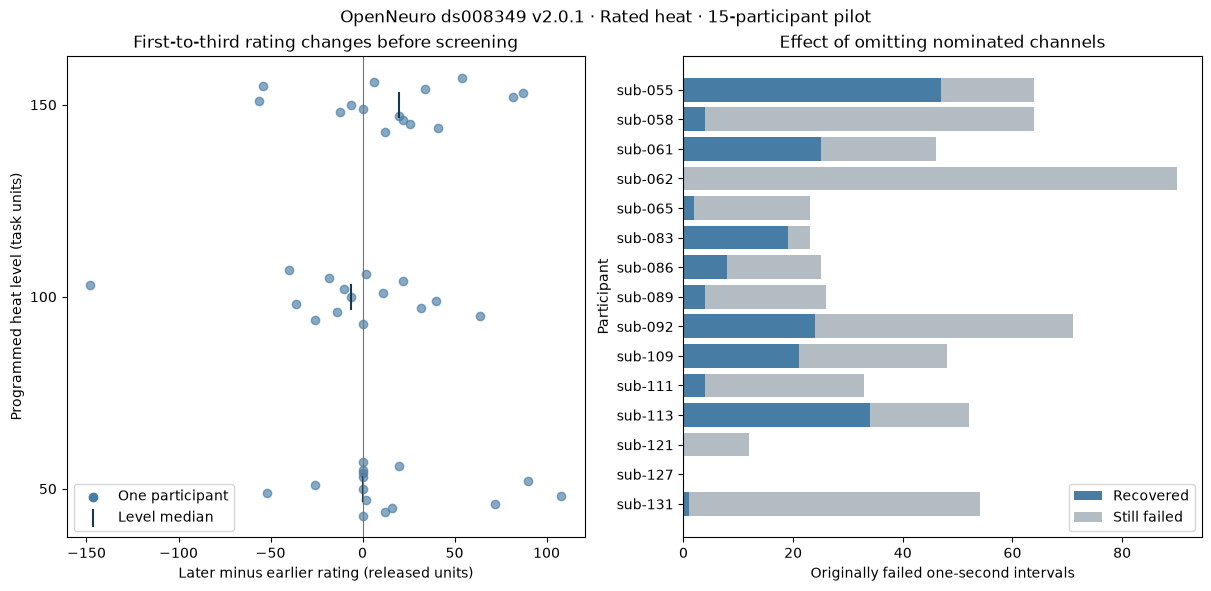

In [9]:
order_rechecked = number_repeats(rechecked_kept)
first_to_third = order_rechecked.loc[
    order_rechecked["First repeat"].eq(1) & order_rechecked["Second repeat"].eq(3)
]
values = first_to_third["Signed change after"]
print(f"First-to-third after channel omissions: median {values.median():+.1f} units, "
      f"{len(values)} pairs from {first_to_third['Participant'].nunique()} participants.")
print(f"Later lower: {values.lt(0).sum()}; same: {values.eq(0).sum()}; later higher: {values.gt(0).sum()}.")

adjusted_rechecked = shared_order_errors(order_rechecked, "Signed change after")
print("Median error on comparable pairs after channel omissions")
display(adjusted_rechecked[["No-change error", "Shared-order error"]].median().round(2))

first_to_third_all = order.loc[order["First repeat"].eq(1) & order["Second repeat"].eq(3)]
figure, (change_axis, eeg_axis) = plt.subplots(1, 2, figsize=(12, 5.8), layout="constrained")
for position, (level, group) in enumerate(first_to_third_all.groupby("Level")):
    gaps = group.sort_values("Participant")["Signed change before"]
    spacing = np.linspace(-0.14, 0.14, len(gaps))
    change_axis.scatter(gaps, position + spacing, color="#477ca5", alpha=0.65)
    change_axis.scatter(gaps.median(), position, marker="|", s=350, color="#16384d")
change_axis.axvline(0, color="0.45", linewidth=0.8)
change_axis.set(
    title="First-to-third rating changes before screening",
    xlabel="Later minus earlier rating (released units)",
    ylabel="Programmed heat level (task units)",
    yticks=range(3), yticklabels=[50, 100, 150],
)
change_axis.scatter([], [], color="#477ca5", label="One participant")
change_axis.scatter([], [], marker="|", s=180, color="#16384d", label="Level median")
change_axis.legend(loc="lower left")

recovered = channel_summary["Recovered_seconds"]
still_failed = channel_summary["Failed_seconds"] - recovered
eeg_axis.barh(channel_summary.index, recovered, color="#477ca5", label="Recovered")
eeg_axis.barh(channel_summary.index, still_failed, left=recovered, color="#b3bcc3", label="Still failed")
eeg_axis.set(title="Effect of omitting nominated channels",
             xlabel="Originally failed one-second intervals", ylabel="Participant")
eeg_axis.invert_yaxis()
eeg_axis.legend(loc="lower right")
figure.suptitle("OpenNeuro ds008349 v2.0.1 · Rated heat · 15-participant pilot")
plt.show()

**Interpretation.** The common sequence yielded both higher and lower ratings at later repeats. A shared order pattern did not improve the held-out comparisons under the primary screen. The plateau timing also showed a median change of zero, with smaller groups of rises and falls. The fixed order leaves elapsed time, repetition and preceding heat inseparable, so individual adaptation remains possible.

A small set of EEG channels accounted for a meaningful share of exclusions. The sensitivity check doubled the retained pairs and kept the median of participant medians at 20 units. Frequently nominated frontal channels may pick up eye activity. The channel omission diagnostic alone cannot identify defective electrodes or establish an artifact-correction rule.

## Eye channels and a consistent EEG screen

An eye movement can create a large, slow deflection at the front of the scalp. Compare the two recorded eye leads (EOG) with frontopolar and anterior frontal EEG. Use the recorded EOG labels because the dataset documents lead swaps and polarity corrections on some recordings. A simultaneous deflection is evidence consistent with an ocular contribution. A failed EEG window can also include muscle activity, movement, line noise or an electrode problem.

We filter only for diagnosis, using a buffered **1–10 Hz** copy of the eye and frontal signals. Flag an eye-channel swing of at least **100 µV** peak to peak in a second. For a frontal EEG failure, call the eye and frontal waveforms similar if their same-second absolute correlation reaches **0.60**. These are pilot criteria. They do not certify each event as a blink. A separate 60 Hz notch-only check asks how often removal of line-frequency energy changes a scalp EEG screening decision.

In [10]:
from scipy import signal

central = ("C3", "Cz", "C4")
neighbors = {
    "C3": ("C1", "C5", "FC3", "CP3"),
    "C4": ("C2", "C6", "FC4", "CP4"),
}
protected = set(central).union(*(set(group) for group in neighbors.values()))
eye_channels = ("HEOG", "VEOG")
diagnostic_rows, plot_candidates, nominations = [], [], []
reference_values = set()

for subject in participants:
    raw, eeg, events, prefix, fs = open_heat_run(subject)
    acquisition = json.loads(Path(f"{prefix}_eeg.json").read_text())
    reference_values.add(acquisition["EEGReference"])
    assert protected.issubset(eeg) and set(eye_channels).issubset(raw.ch_names), subject
    frontal = [name for name in eeg if name.startswith(("Fp", "AF"))]
    frontal_idx = [eeg.index(name) for name in frontal]
    eye_filter = signal.butter(3, [1, 10], fs=fs, btype="bandpass", output="sos")
    notch_b, notch_a = signal.iirnotch(60, Q=30, fs=fs)
    failure_counts = np.zeros(len(eeg), dtype=int)
    segments = []

    for _, event in events.iloc[:-1].iterrows():
        block = event["trial_type"].split("/")[0]
        sample = int(event["sample"])
        # Read a buffer on both ends before applying zero-phase diagnostic filters.
        data = raw.get_data(picks=eeg + list(eye_channels), start=sample + 12 * fs, stop=sample + 38 * fs)
        analysis = slice(3 * fs, 23 * fs)  # event-relative seconds 15–35
        scalp = data[:len(eeg)]
        amplitude, failed = peak_to_peak_failures(scalp[:, analysis].reshape(len(eeg), 20, fs))
        failure_counts += failed[:, :10].sum(axis=1)
        notch = signal.filtfilt(notch_b, notch_a, scalp, axis=1)
        _, notch_failed = peak_to_peak_failures(notch[:, analysis].reshape(len(eeg), 20, fs))

        low = signal.sosfiltfilt(eye_filter, data[frontal_idx + [-2, -1]], axis=1)[:, analysis]
        low_seconds = low.reshape(len(frontal) + 2, 20, fs)
        eye_low = np.ptp(low_seconds[-2:], axis=2).max(axis=0) * 1e6
        centered = low_seconds - low_seconds.mean(axis=2, keepdims=True)
        scales = np.linalg.norm(centered, axis=2, keepdims=True)
        normalized = np.divide(centered, scales, out=np.zeros_like(centered), where=scales > 0)
        correlations = np.abs(np.einsum("fst,est->fes", normalized[:-2], normalized[-2:]))

        # Preserve the original reference and use identical one-second Hann spectra
        # at the target sites for reliability only. This cell never joins power to ratings.
        central_seconds = scalp[[eeg.index(name) for name in central], analysis].reshape(3, 20, fs)
        freq, psd = signal.periodogram(central_seconds, fs=fs, window="hann", axis=2, detrend="constant")
        band = (freq >= 8) & (freq <= 13)
        central_log = np.log(psd[:, :, band].sum(axis=2)).mean(axis=0)
        raw_centers = scalp[[eeg.index(name) for name in neighbors]]
        local_centers = np.stack([
            scalp[eeg.index(name)] - scalp[[eeg.index(ch) for ch in adjacent]].mean(axis=0)
            for name, adjacent in neighbors.items()
        ])
        local_seconds = local_centers[:, analysis].reshape(2, 20, fs)
        _, local_psd = signal.periodogram(local_seconds, fs=fs, window="hann", axis=2)
        local_log = np.log(local_psd[:, :, band].sum(axis=2)).mean(axis=0)
        local_eye = signal.sosfiltfilt(eye_filter, np.vstack([raw_centers, local_centers]), axis=1)
        local_eye = local_eye[:, analysis].reshape(4, 20, fs)
        centered_local = local_eye - local_eye.mean(axis=2, keepdims=True)
        scale_local = np.linalg.norm(centered_local, axis=2, keepdims=True)
        local_normalized = np.divide(centered_local, scale_local, out=np.zeros_like(centered_local), where=scale_local > 0)
        central_eye_corr = np.abs(np.einsum("cst,est->ces", local_normalized, normalized[-2:]))
        central_eye_corr = central_eye_corr.max(axis=1).reshape(2, 2, 20).mean(axis=1)
        eog_raw = data[-2:, analysis].reshape(2, 20, fs)
        eog_freq, eog_psd = signal.periodogram(eog_raw, fs=fs, window="hann", axis=2)
        mains = (eog_freq >= 59) & (eog_freq <= 61)
        wide = (eog_freq >= 1) & (eog_freq <= 100)
        eog_mains_fraction = (eog_psd[:, :, mains].sum(axis=2) / eog_psd[:, :, wide].sum(axis=2)).max(axis=0)
        rating = raw.get_data(picks=["rating"], start=sample + 25 * fs, stop=sample + 35 * fs)
        rating_span = np.ptp(rating.reshape(10, fs), axis=1)
        segments.append((block, sample, failed, notch_failed, eye_low, correlations, central_log,
                         local_log, central_eye_corr, eog_mains_fraction, rating_span))

    # The calibration intervals use only EEG amplitudes and precede the analysis
    # intervals. Always preserve the three electrodes in the primary power measure.
    ranked = sorted(
        (index for index, name in enumerate(eeg) if name not in protected and failure_counts[index] > 0),
        key=lambda index: (-failure_counts[index], eeg[index]),
    )
    omitted = ranked[:2]
    keep = np.ones(len(eeg), dtype=bool)
    keep[omitted] = False
    nominations.append({"Participant": subject, "Channels omitted": ", ".join(eeg[i] for i in omitted)})

    for block, sample, failed, notch_failed, eye_low, correlations, central_log, local_log, center_corr, mains_fraction, rating_span in segments:
        for relative_second in range(25, 35):
            index = relative_second - 15
            failed_front = failed[frontal_idx, index]
            any_frontal = bool(failed_front.any())
            # For a failed frontal second, compare only the failed frontal channels.
            matched_corr = correlations[failed_front, :, index] if any_frontal else correlations[:, :, index]
            best_corr = float(matched_corr.max())
            eye_linked = eye_low[index] >= 100 and best_corr >= 0.60
            row = {
                "Participant": subject, "Block": block, "Second": relative_second,
                "Full EEG failed": bool(failed[:, index].any()),
                "Frontal failed": any_frontal, "EOG swing µV": float(eye_low[index]),
                "EOG correlation": best_corr, "Eye-linked": bool(eye_linked),
                "After 60 Hz notch passes": bool(~notch_failed[:, index].any()),
                "EOG 60 Hz fraction": float(mains_fraction[index]),
                "EEG passes after omission": bool(~failed[keep, index].any()),
                "Rating steady": bool(rating_span[relative_second - 25] <= 1),
                "Central log alpha": float(central_log[index]),
                "Local log alpha": float(local_log[index]),
                "Central EOG correlation": float(center_corr[0, index]),
                "Local EOG correlation": float(center_corr[1, index]),
            }
            if any_frontal and eye_linked:
                frontal_choice, eye_choice = np.unravel_index(matched_corr.argmax(), matched_corr.shape)
                plot_candidates.append((best_corr, subject, block, sample, relative_second,
                                        np.asarray(frontal)[failed_front][frontal_choice], eye_channels[eye_choice]))
            diagnostic_rows.append(row)

eyes = pd.DataFrame(diagnostic_rows)
assert reference_values == {"FCz"} and len(eyes) == len(windows)
assert np.array_equal(eyes["Full EEG failed"], ~eeg_pass)
frontal_failures = eyes["Frontal failed"]
passes_full = ~eyes["Full EEG failed"]
print(f"Original failed EEG seconds: {eyes['Full EEG failed'].sum()}")
print(f"Frontal failed: {frontal_failures.sum()}; eye-linked among them: {eyes.loc[frontal_failures, 'Eye-linked'].sum()}")
print(f"All 63 scalp channels passed: {passes_full.sum()}; eye-linked among them: {eyes.loc[passes_full, 'Eye-linked'].sum()}")
print(f"Recovered by 60 Hz notch alone: {(eyes['Full EEG failed'] & eyes['After 60 Hz notch passes']).sum()}")
print(f"Median largest 59–61 Hz share of the two EOG leads' 1–100 Hz power: {eyes['EOG 60 Hz fraction'].median():.1%}")
by_person = eyes.groupby(["Participant", "Frontal failed"])["Eye-linked"].mean().unstack()
print(f"Median paired increase in eye linkage for frontal failures: {(by_person[True] - by_person[False]).median():.1%}")

Original failed EEG seconds: 631
Frontal failed: 526; eye-linked among them: 447
All 63 scalp channels passed: 719; eye-linked among them: 188
Recovered by 60 Hz notch alone: 16
Median largest 59–61 Hz share of the two EOG leads' 1–100 Hz power: 2.4%
Median paired increase in eye linkage for frontal failures: 57.6%


## Does screening for eye activity preserve within-temperature rating gaps?

Keep the same temperature and timing match. In every participant, rank EEG channels by failures in seconds **15–25** and omit up to two failing channels. Preserve C3, Cz, C4 and the fixed neighbors used to re-reference C3/C4. In the separate **25–35-second** intervals, require all remaining scalp channels to pass **0.5–150 µV** and both filtered eye channels to stay below the eye threshold. Drop the affected seconds without subtracting an eye signal from the EEG.

Also restrict to seconds with at most one rating unit of movement on the rating trace. This is an imperfect proxy for periods where the participant was not moving the rating control. It reduces a possible motor confound. Apply the same rule to both blocks in each comparison. Repeat at 75 and 150 µV EOG thresholds to show sensitivity.

In [11]:
diagnostics = windows.merge(eyes, on=["Participant", "Block", "Second"], validate="one_to_one")
assert diagnostics["Central log alpha"].map(np.isfinite).all()
assert np.array_equal(diagnostics["EEG passes after omission"], rechecked["Passed after omitting nominees"])

def compare_screen(passes):
    screen = diagnostics.assign(**{
        "All channels finite and above floor": passes,
        "Maximum channel µV": 0.0,
    })
    pairs = []
    for (subject, level), group in screen.groupby(["Participant", "Level"]):
        for (block_a, a), (block_b, b) in combinations(list(group.groupby("Block")), 2):
            pairs.append((subject, int(level), block_a, block_b, a, b))
    return compare_pairs(block_pairs=pairs)

scalp_pass = diagnostics["EEG passes after omission"]
steady = diagnostics["Rating steady"]
eye_amplitude = diagnostics["EOG swing µV"]
conditions = {
    "EEG only": scalp_pass,
    "EEG and eye screen": scalp_pass & eye_amplitude.lt(100),
    "EEG, eye screen and stable ratings": scalp_pass & eye_amplitude.lt(100) & steady,
    "Same rule with 75 µV eye threshold": scalp_pass & eye_amplitude.lt(75) & steady,
    "Same rule with 150 µV eye threshold": scalp_pass & eye_amplitude.lt(150) & steady,
}
rule_rows, comparison_by_rule = [], {}
for name, passes in conditions.items():
    comparisons = compare_screen(passes)
    comparison_by_rule[name] = comparisons
    p_summary = participant_summary(comparisons)
    kept = comparisons.dropna(subset=["Rating gap after"])
    rule_rows.append({
        "Rule": name, "Seconds passing": int(passes.sum()), "Pairs": len(kept),
        "Participants": len(kept["Participant"].unique()),
        "Median pair gap": kept["Rating gap after"].median(),
        "Median of participant medians": p_summary["median_gap"].median(),
    })

eye_screen_summary = pd.DataFrame(rule_rows)
display(eye_screen_summary.round(2))
confirmatory_mask = conditions["EEG, eye screen and stable ratings"]
eye_screen_pairs = comparison_by_rule["EEG, eye screen and stable ratings"]
kept_eye_pairs = eye_screen_pairs.dropna(subset=["Rating gap after"])
per_person_gap = participant_summary(eye_screen_pairs)["median_gap"].dropna()
leave_one_out = [per_person_gap.drop(subject).median() for subject in per_person_gap.index]
print(f"Participant-weighted median after leaving out each contributing person: {min(leave_one_out):.1f}–{max(leave_one_out):.1f} units.")
print(f"People with a retained gap of at least 20 units: {kept_eye_pairs.groupby('Participant')['Rating gap after'].max().ge(20).sum()}.")
print(f"Distinct participant × heat levels with a retained comparison: {kept_eye_pairs.groupby(['Participant', 'Level']).ngroups}.")
print(f"Metadata-eligible participants outside all pilot analyses: {int(eligible.sum()) - len(new)}.")

,Rule,Seconds passing,Pairs,Participants,Median pair gap,Median of participant medians
0,EEG only,912,82,11,18.0,20.0
1,EEG and eye screen,634,35,7,12.0,23.0
2,"EEG, eye screen and stable ratings",604,35,7,12.0,20.0
3,Same rule with 75 µV eye threshold,565,34,6,12.0,16.0
4,Same rule with 150 µV eye threshold,678,41,8,6.0,3.0


Participant-weighted median after leaving out each contributing person: 14.5–21.5 units.
People with a retained gap of at least 20 units: 5.
Distinct participant × heat levels with a retained comparison: 15.
Metadata-eligible participants outside all pilot analyses: 59.


## Check central alpha measurement repeatability before testing the association

For each block with at least five seconds passing the combined rule, split the retained seconds into alternating groups. Average the independently measured **8–13 Hz** log power at C3, Cz and C4 within each group. Subtract each participant's mean separately from each half before comparing the halves, so stable differences between people cannot drive the correlation. This describes internal repeatability within the sampled session. It is not an estimate of test–retest reliability across visits.

The figure shows a frontal/EOG example selected by their largest waveform similarity among the failed frontal windows. The displayed series are mean-centered and divided by their own standard deviation. The thresholds were applied in microvolts before this display scaling.

Blocks with at least five usable seconds: 64 from 12 participants.
Within-person split-half alpha correlation: 0.46, using 63 blocks from 11 participants.


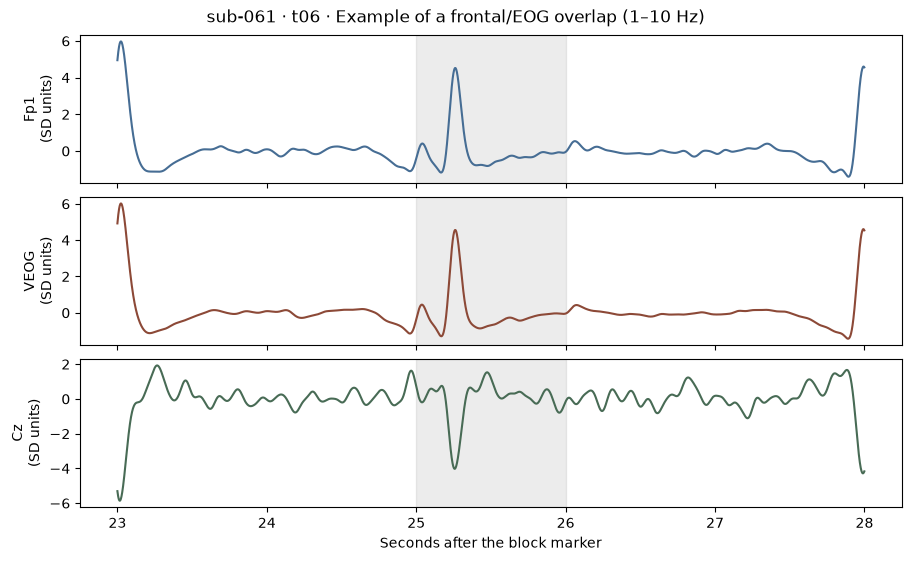

In [12]:
split_rows = []
for (subject, block), segment in diagnostics.loc[confirmatory_mask].groupby(["Participant", "Block"]):
    power = segment.sort_values("Second")["Central log alpha"].to_numpy()
    if len(power) >= 5:
        split_rows.append({
            "Participant": subject, "Block": block,
            "Alternating half A": power[::2].mean(), "Alternating half B": power[1::2].mean(),
        })
split = pd.DataFrame(split_rows)
formula_columns = ["Alternating half A", "Alternating half B"]
counts = split.groupby("Participant")["Block"].transform("size")
multi = split.loc[counts.ge(2)]
centered_halves = multi[formula_columns] - multi.groupby("Participant")[formula_columns].transform("mean")
within_person_r = centered_halves.corr().iloc[0, 1]
print(f"Blocks with at least five usable seconds: {len(split)} from {split['Participant'].nunique()} participants.")
print(f"Within-person split-half alpha correlation: {within_person_r:.2f}, using {len(multi)} blocks from {multi['Participant'].nunique()} participants.")

corr, subject, block, sample, second, front_name, eye_name = max(plot_candidates)
example_raw, _, _, _, fs = open_heat_run(subject)
example_names = [front_name, eye_name, "Cz"]
excerpt = example_raw.get_data(picks=example_names, start=sample + (second-5)*fs, stop=sample + (second+6)*fs)
sos = signal.butter(3, [1, 10], fs=fs, btype="bandpass", output="sos")
slow = signal.sosfiltfilt(sos, excerpt, axis=1)[:, 3*fs:8*fs]
z = (slow - slow.mean(axis=1, keepdims=True)) / slow.std(axis=1, keepdims=True)
time = np.arange(z.shape[1]) / fs + second - 2
fig, axes = plt.subplots(3, 1, figsize=(9, 5.5), sharex=True, layout="constrained")
for axis, values, name, color in zip(axes, z, example_names, ["#466d94", "#8c4937", "#486b55"]):
    axis.plot(time, values, color=color)
    axis.axvspan(second, second + 1, color="0.5", alpha=0.15)
    axis.set_ylabel(f"{name}\n(SD units)")
axes[-1].set_xlabel("Seconds after the block marker")
fig.suptitle(f"{subject} · {block} · Example of a frontal/EOG overlap (1–10 Hz)")
plt.show()

## Check whether the comparison can distinguish ratings from nuisance variables

Use the same 100 µV eye-screen rule and retain the original pairs. First compare the same pairs with and without the eye and stable-rating rules to check how much the rule itself changed the gaps. Then check how much signed rating variation remains after removing linear temperature differences and the shared level-by-repeat pattern. This step uses the ratings and temperature. It does not pair any EEG power values with ratings.

For the power measurement, split the common retained seconds in each block pair into alternating halves. Compare the estimated later-minus-earlier alpha changes in the two halves. The centrally recorded example shares an eye deflection, so also test a fixed local reference that subtracts four neighboring electrodes from each of C3 and C4. The subtraction cancels the common FCz reference. Compare eye coupling and repeatability without testing an association between power and ratings.

In [13]:
pair_keys = ["Participant", "Level", "First block", "Second block"]
same_pairs = kept_eye_pairs.merge(
    rechecked_kept[pair_keys + ["Rating gap after"]], on=pair_keys, validate="one_to_one",
    suffixes=("", " without eye or stable-rating screen"),
)
before = same_pairs["Rating gap after without eye or stable-rating screen"]
after = same_pairs["Rating gap after"]
print(f"The same {len(same_pairs)} pairs had median gaps of {before.median():.1f} before and {after.median():.1f} after adding the eye and stable-rating rules.")
looser_eye_pairs = comparison_by_rule["Same rule with 150 µV eye threshold"].dropna(subset=["Rating gap after"])
common_eye_pairs = kept_eye_pairs.merge(looser_eye_pairs[pair_keys + ["Rating gap after"]],
                                       on=pair_keys, validate="one_to_one", suffixes=("_100", "_150"))
print(f"100 and 150 µV rules share {len(common_eye_pairs)} pairs; median gaps on those pairs: "
      f"{common_eye_pairs['Rating gap after_100'].median():.1f} and {common_eye_pairs['Rating gap after_150'].median():.1f} units.")

model_pairs = number_repeats(kept_eye_pairs)
schedule = model_pairs[["Level", "First repeat", "Second repeat"]].astype(str).agg(" / ".join, axis=1)
schedule_terms = pd.get_dummies(schedule).to_numpy(dtype=float)
delta_temperature = model_pairs["Second temperature after (°C)"] - model_pairs["First temperature after (°C)"]
nuisance = np.column_stack([schedule_terms, delta_temperature])
observed = model_pairs["Signed change after"].to_numpy()
fitted = nuisance @ np.linalg.lstsq(nuisance, observed, rcond=None)[0]
remaining = observed - fitted
print(f"After accounting for temperature and shared order, median absolute residual rating change: {np.median(np.abs(remaining)):.1f} units.")
print(f"Adding the rating contrast increases design rank from {np.linalg.matrix_rank(nuisance)} to "
      f"{np.linalg.matrix_rank(np.column_stack([nuisance, observed]))}.")

# Compare whether the eye gate preferentially loses one end of the observed rating range.
candidate_seconds = diagnostics.loc[scalp_pass & steady].copy()
groups = candidate_seconds.groupby(["Participant", "Level"])
center = groups["Rating"].transform("median")
candidate_seconds["Relative rating"] = np.where(
    candidate_seconds["Rating"] > center, "above", np.where(candidate_seconds["Rating"] < center, "below", "at median")
)
candidate_seconds["Eye screen passes"] = candidate_seconds["EOG swing µV"].lt(100)
rating_pass = candidate_seconds.loc[candidate_seconds["Relative rating"].ne("at median")].groupby(
    ["Participant", "Level", "Relative rating"]
)["Eye screen passes"].agg(["mean", "size"]).unstack()
enough = rating_pass["size"].fillna(0).min(axis=1) >= 5
difference = (rating_pass["mean"]["above"] - rating_pass["mean"]["below"])[enough]
person_differences = difference.groupby("Participant").median()
print(f"Eye-screen retention, above minus below each person-level rating median: "
      f"median {person_differences.median():+.1%} across {len(person_differences)} people ({len(difference)} groups).")

available = diagnostics.assign(Passes=confirmatory_mask).set_index(["Participant", "Block", "Second"]).sort_index()
assert available.index.is_unique
for power in ["Central log alpha", "Local log alpha"]:
    pair_power_halves = []
    for _, pair in kept_eye_pairs.iterrows():
        a = available.loc[(pair["Participant"], pair["First block"])]
        b = available.loc[(pair["Participant"], pair["Second block"])]
        common = (a["Passes"] & b["Passes"] & a["Labels valid"] & b["Labels valid"]
                  & ((a["Temperature °C"] - b["Temperature °C"]).abs() <= 0.10 + 1e-9))
        assert int(common.sum()) == pair["Retained seconds"]
        alpha_delta = (b[power] - a[power])[common].to_numpy()
        pair_power_halves.append({"Participant": pair["Participant"],
                                  "Alternating half A": alpha_delta[::2].mean(),
                                  "Alternating half B": alpha_delta[1::2].mean()})
    contrast_halves = pd.DataFrame(pair_power_halves)
    print(f"{power} split-half correlation of pair changes: {contrast_halves[formula_columns].corr().iloc[0, 1]:.2f} ({len(contrast_halves)} pairs).")
coupling = diagnostics.loc[confirmatory_mask, ["Central EOG correlation", "Local EOG correlation"]]
print(f"Median slow EOG coupling in retained seconds, C3/C4 with the original FCz reference and local reference: "
      f"{coupling.iloc[:, 0].median():.2f} and {coupling.iloc[:, 1].median():.2f}.")

The same 35 pairs had median gaps of 12.0 before and 12.0 after adding the eye and stable-rating rules.
100 and 150 µV rules share 35 pairs; median gaps on those pairs: 12.0 and 12.0 units.
After accounting for temperature and shared order, median absolute residual rating change: 16.9 units.
Adding the rating contrast increases design rank from 10 to 11.
Eye-screen retention, above minus below each person-level rating median: median +0.0% across 11 people (20 groups).
Central log alpha split-half correlation of pair changes: 0.60 (35 pairs).
Local log alpha split-half correlation of pair changes: 0.59 (35 pairs).
Median slow EOG coupling in retained seconds, C3/C4 with the original FCz reference and local reference: 0.35 and 0.28.


## Selected hypothesis for the untouched cohort

**Within a person at the same programmed heat level and nearly the same measured temperature, differences in reported pain between repeated plateaus are associated with differences in locally referenced C3/C4 alpha power (8–13 Hz), after accounting for measured temperature differences and the shared repeat pattern.**

Use a **two-sided** test. Published heat studies differ on whether alpha more closely follows delivered heat or subjective pain. A two-sided test targets a single prespecified association without choosing its direction from the pilot. The pilot verified power repeatability and usable rating variation independently.

### Confirmation analysis to lock before examining relationships in new recordings

- Use the 59 metadata-eligible participants outside the pilot. The usable count will depend on screening. Report exclusions and retained counts by participant and heat level.
- Keep the matching rule fixed. Compare the same seconds during the 25–35-second interval of repeated blocks at the same programmed level. Require at least five common seconds within 0.10°C. Rank scalp channels on 15–25 seconds, omit up to two failing channels per person outside the protected montage, apply the 0.5–150 µV EEG limits and 100 µV filtered EOG limit, and require the rating trace to vary by at most one unit in each retained second.
- Subtract the mean of C1, C5, FC3 and CP3 from C3, and the mean of C2, C6, FC4 and CP4 from C4. For each second, compute Hann-windowed power at the inclusive 8–13 Hz bins, take the natural log after summing the one-Hz bins at each site, and average the two sites. Take the mean across the matched seconds in each block. Take the median rating and median temperature over the same seconds.
- Model later-minus-earlier log alpha as a function of later-minus-earlier rating and temperature, with categorical terms for programmed level crossed with repeat contrast. Give each participant equal total weight. Estimate a two-sided 95% interval for the rating coefficient by resampling participants as clusters, keeping all each person's pairs together. Report the effect per 10 released rating units. Check direction and size with 75 and 150 µV eye limits and with the residual difference in slow EOG amplitude included as a covariate.
- Interpret the result as a within-task association. The common order prevents separating individual adaptation from time and prior stimulation, and rating-related attention or movement may persist. A subsequent sound comparison would address how specific the association is to heat pain.

Research context: [tonic heat and alpha changes](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0091052), [heat intensity and pain ratings in tonic EEG](https://eprints.gla.ac.uk/134661/7/134661.pdf), and [MNE's guide to eye and line artifacts](https://mne.tools/stable/auto_tutorials/preprocessing/10_preprocessing_overview.html).